In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("/content/healthcare-dataset-stroke-data.csv");
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df = df.drop('id',axis =1)

In [5]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [6]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [10]:
cat_cols = ['gender','hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type','smoking_status']
unique_values = {col:df[col].unique() for col in cat_cols}

In [12]:
for col, values in unique_values.items():
  print(f'{col} : {values}')

gender : ['Male' 'Female' 'Other']
hypertension : [0 1]
heart_disease : [1 0]
ever_married : ['Yes' 'No']
work_type : ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type : ['Urban' 'Rural']
smoking_status : ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [15]:
num_cats = ['age','avg_glucose_level','bmi']
df[num_cats].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


In [16]:
round(df[df['gender'] == 'Male']['stroke'].mean()*100,2)

np.float64(5.11)

In [17]:
round(df[df['gender'] == 'Female']['stroke'].mean()*100,2)

np.float64(4.71)

**Distribution: Age**

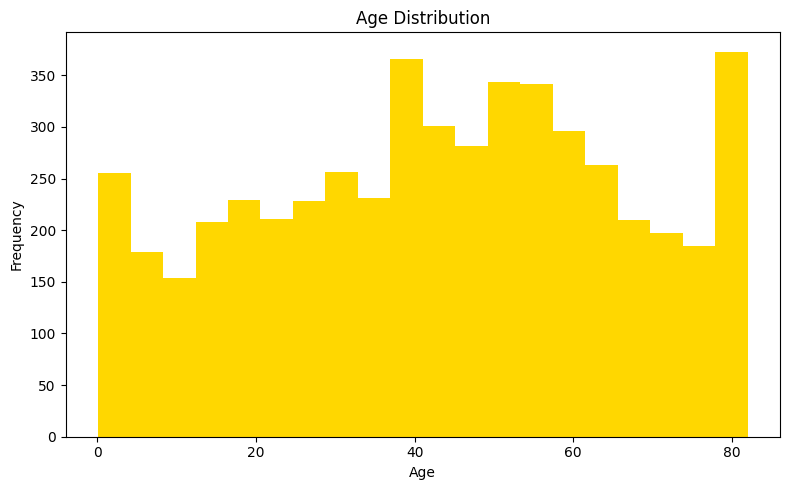

In [54]:
plt.figure(figsize=(8,5))
plt.hist(df["age"], bins=20,color="gold")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.tight_layout()
plt.show()

In [21]:
# Observation:
# - Age ranges from 0 to 82.
# - More middle-aged and older individuals.

**Glucose Level Distribution**

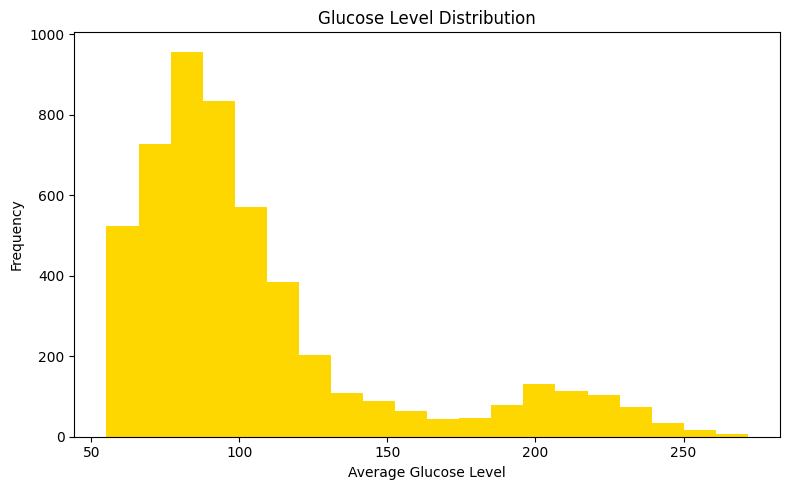

In [53]:
plt.figure(figsize=(8,5))
plt.hist(df["avg_glucose_level"], bins=20,color="gold")
plt.xlabel("Average Glucose Level")
plt.ylabel("Frequency")
plt.title("Glucose Level Distribution")
plt.tight_layout()
plt.show()


In [20]:
# Observation:
# - Right-skewed distribution.
# - Most people between 60–120 mg/dL.
# - Some have glucose >200 which increases stroke risk.

**BMI Distribution**

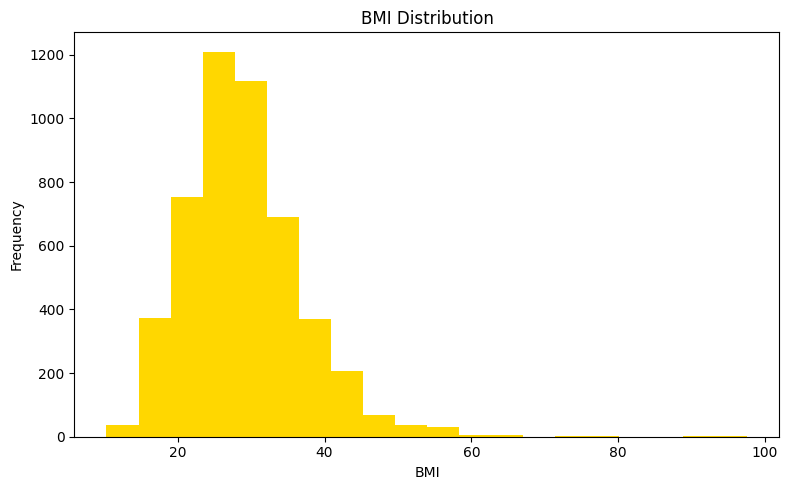

In [52]:
plt.figure(figsize=(8,5))
plt.hist(df["bmi"].dropna(), bins=20,color="gold")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution")
plt.tight_layout()
plt.show()

In [ ]:
# Observation:
# - BMI mostly between 20–35.
# - Some extreme or missing values we will handle it later.

**Stoke Distribution**

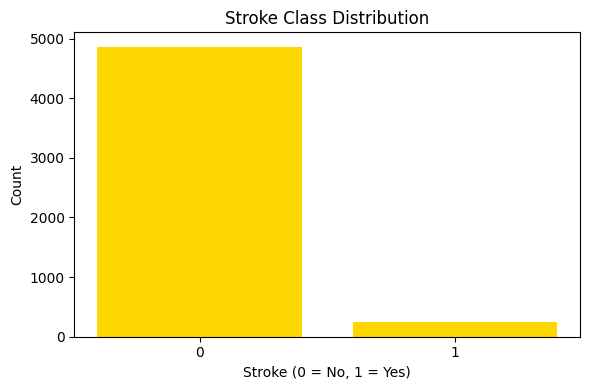

In [51]:
stroke_counts = df["stroke"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(stroke_counts.index.astype(str), stroke_counts.values, color="gold")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.title("Stroke Class Distribution")
plt.tight_layout()
plt.show()

**Age vs Stroke**

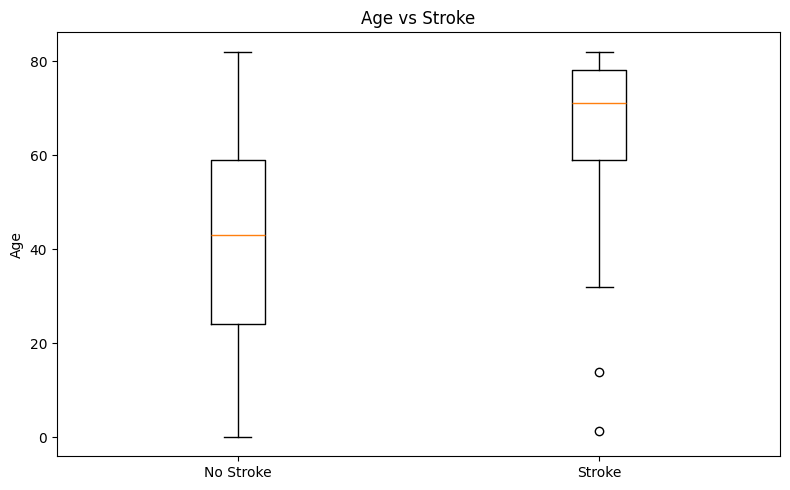

In [25]:
plt.figure(figsize=(8,5))
plt.boxplot([df[df["stroke"]==0]["age"], df[df["stroke"]==1]["age"]], labels=["No Stroke", "Stroke"])
plt.title("Age vs Stroke")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

In [26]:
# Observation:
# - Stroke patients are generally older.

**Glucose Level vs Stroke**

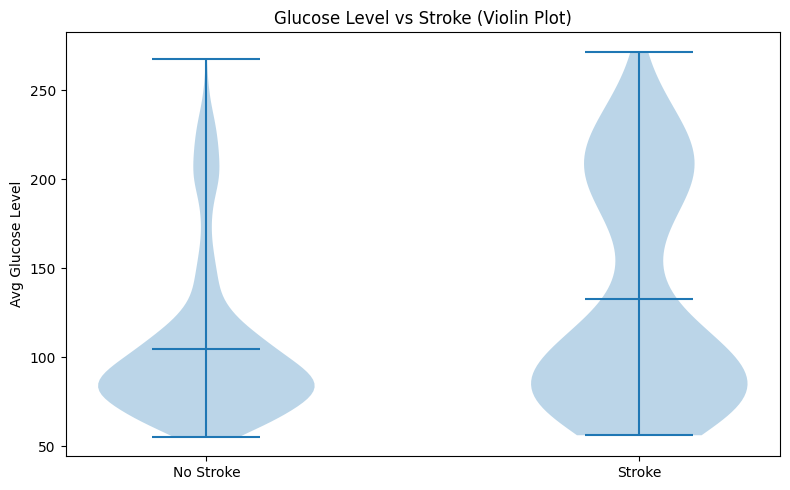

In [48]:
plt.figure(figsize=(8,5))
plt.violinplot([
    df[df["stroke"]==0]["avg_glucose_level"],
    df[df["stroke"]==1]["avg_glucose_level"]
], showmeans=True,)

plt.xticks([1,2], ["No Stroke", "Stroke"])
plt.ylabel("Avg Glucose Level")
plt.title("Glucose Level vs Stroke (Violin Plot)")
plt.tight_layout()
plt.show()


In [30]:
# Observation:
# - Stroke patients show higher glucose levels.

**Distribution of Work Types**

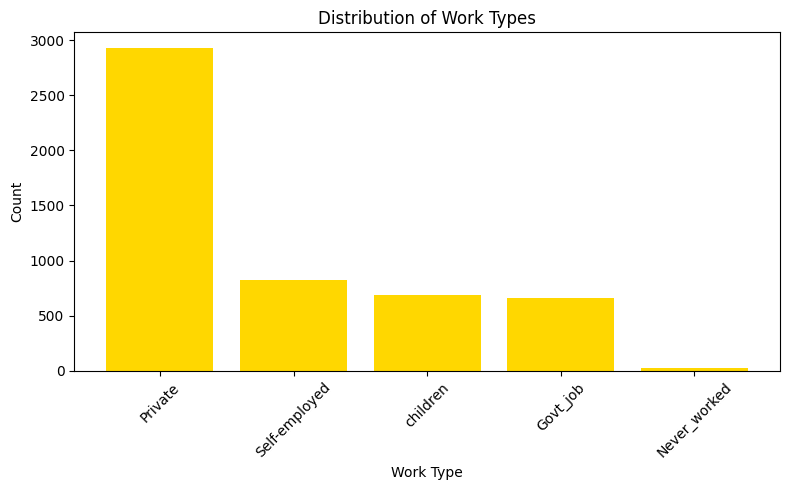

In [46]:
work_counts = df["work_type"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(work_counts.index, work_counts.values,color="gold")
plt.xlabel("Work Type")
plt.ylabel("Count")
plt.title("Distribution of Work Types")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [32]:
# Observation:
# Most people (57%) work in the Private sector.
# Children and Never_worked are very small categories.
# Dataset is dominated by working adults.

**Stroke Rate by Work Type**

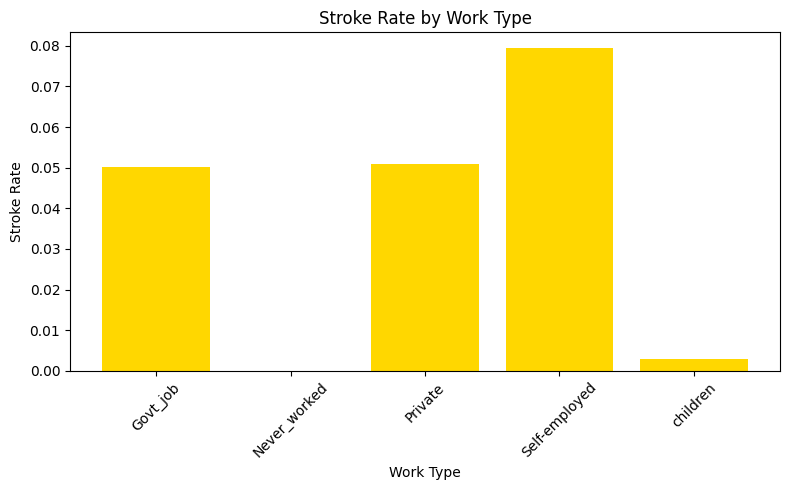

In [45]:
stroke_by_work = df.groupby("work_type")["stroke"].mean()

plt.figure(figsize=(8,5))
plt.bar(stroke_by_work.index, stroke_by_work.values, color="gold")
plt.xlabel("Work Type")
plt.ylabel("Stroke Rate")
plt.title("Stroke Rate by Work Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [34]:
# Observation:
# Self-employed people have the highest stroke rate.
# Children and Never_worked have almost no stroke cases (makes sense due to young age).
# Govt_job and Private are in moderate range.

**Marriage Status**

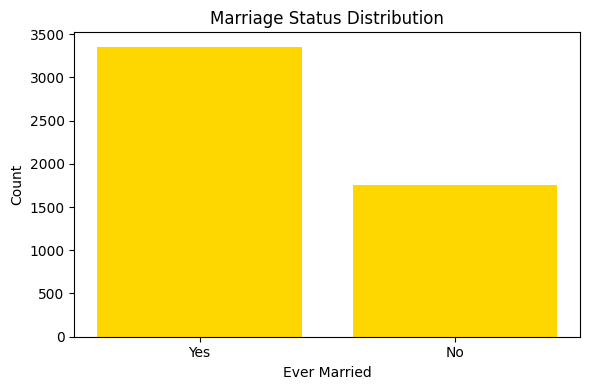

In [44]:
mar_counts = df["ever_married"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(mar_counts.index, mar_counts.values , color="gold")
plt.xlabel("Ever Married")
plt.ylabel("Count")
plt.title("Marriage Status Distribution")
plt.tight_layout()
plt.show()


**Stroke Rate by Marriage Status**

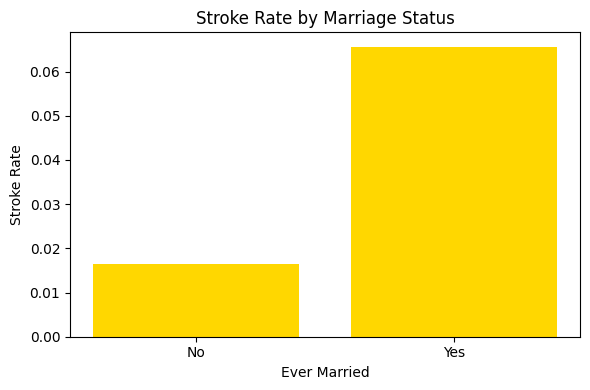

In [43]:
stroke_by_mar = df.groupby("ever_married")["stroke"].mean()

plt.figure(figsize=(6,4))
plt.bar(stroke_by_mar.index, stroke_by_mar.values, color="gold")
plt.xlabel("Ever Married")
plt.ylabel("Stroke Rate")
plt.title("Stroke Rate by Marriage Status")
plt.tight_layout()
plt.show()


In [ ]:
# Observation:
# Married people have 4× higher stroke risk than unmarried.
# This is because married group is much older.
   # Married avg age ≈ 43
   # Not married avg age ≈ 22

**Smoking Status Distribution**

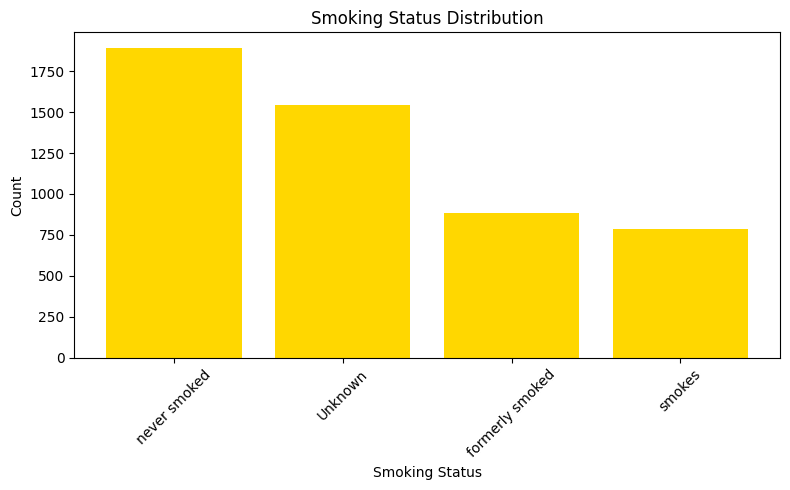

In [42]:
smoke_counts = df["smoking_status"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(smoke_counts.index, smoke_counts.values,color="gold")
plt.xlabel("Smoking Status")
plt.ylabel("Count")
plt.title("Smoking Status Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Stroke Rate by Smoking Status**

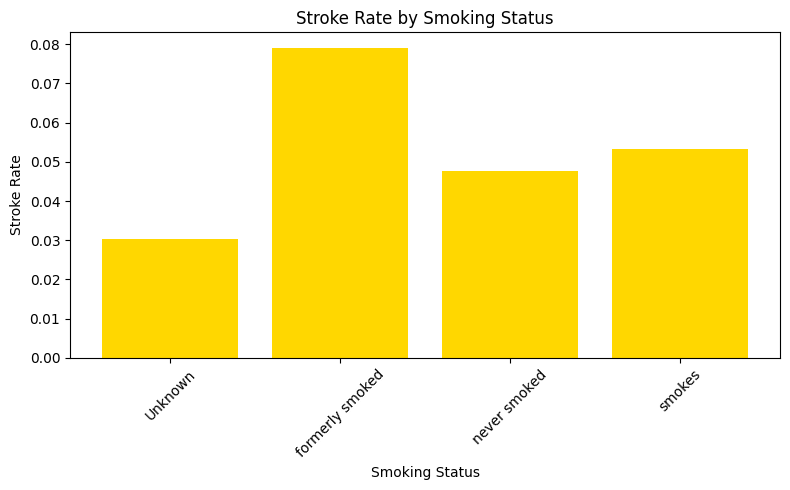

In [55]:
stroke_by_smoke = df.groupby("smoking_status")["stroke"].mean()

plt.figure(figsize=(8,5))
plt.bar(stroke_by_smoke.index, stroke_by_smoke.values,color="gold")
plt.xlabel("Smoking Status")
plt.ylabel("Stroke Rate")
plt.title("Stroke Rate by Smoking Status")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [40]:
# Observation:
# Former smokers have the highest stroke rate — very strong risk indicator.
# Active smokers also show increased risk.
# Never-smokers have the lowest stroke risk.
# Unknown category is mid-level.

**Machine Learning**

In [60]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.preprocessing import PowerTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [64]:
cat_cols = ['hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type','smoking_status']
num_cols = ['age','avg_glucose_level','bmi']


**Numerical & Categorical transformer**

In [65]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),                       #Fill missing values with median
    ('power', PowerTransformer(method='yeo-johnson', standardize=True))  #Deals with skewness(normalize)
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),    #Fill missing values with mode
    ('onehot', OneHotEncoder(handle_unknown='ignore'))       #converts cat to binary format
])

**Column Transformer**

In [67]:
transformer = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cats),
    ('cat', cat_transformer, cat_cols)
])

In [95]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = df.drop('stroke', axis=1)
y = df['stroke']

In [106]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [107]:
full_pipeline = Pipeline([
    ("prep", transformer),                # transforms the data
    ("sm", SMOTE(random_state=42)),       # balances X_train only
])

full_pipeline.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('power',
                                                                   PowerTransformer())]),
                                                  ['age', 'avg_glucose_level',
                                                   'bmi']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['hypertension',
                                                   'heart_disease',
                                                   'ever_married', 'work_type',
                                                   'Residence_type',
                                                   'smoking_status'])])),
                ('sm', SMOTE(random_state=42))])

In [108]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=42)

In [116]:
lr_pipeline = Pipeline([
    ("prep", transformer),
    ("sm", SMOTE(random_state=42)),
    ("model", LogisticRegression(solver="liblinear"))
])

lr_scores = cross_val_score(lr_pipeline, X_test, y_test, scoring="roc_auc", cv=cv, n_jobs=-1)

print("Logistic Regression ROC-AUC:", lr_scores.mean(), "+/-", rf_scores.std())


Logistic Regression ROC-AUC: 0.7845620309979664 +/- 0.1106336967561538


In [114]:
rf_pipeline = Pipeline([
    ("prep", transformer),
    ("sm", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(n_estimators=100))
])

rf_scores = cross_val_score(rf_pipeline, X_test, y_test, scoring="roc_auc", cv=cv, n_jobs=-1)

print("Random Forest ROC-AUC:", rf_scores.mean(), "+/-", rf_scores.std())


Random Forest ROC-AUC: 0.7291770110105898 +/- 0.1106336967561538


In [115]:
lda_pipeline = Pipeline([
    ("prep", transformer),
    ("sm", SMOTE(random_state=42)),
    ("model", LinearDiscriminantAnalysis())
])

lda_scores = cross_val_score(lda_pipeline, X_test, y_test, scoring="roc_auc", cv=cv, n_jobs=-1)

print("LDA ROC-AUC:", lda_scores.mean(), "+/-", lda_scores.std())


LDA ROC-AUC: 0.7942779998597378 +/- 0.09719531069625646


In [119]:
'''
Among all models evaluated, Linear Discriminant Analysis (LDA) provides
the most accurate and stable predictions for stroke detection in this dataset.
Logistic Regression performs reasonably well but fluctuates more, while Random Forest
demonstrates comparatively weaker discrimination ability and lower reliability.
'''

'\nAmong all models evaluated, Linear Discriminant Analysis (LDA) provides \nthe most accurate and stable predictions for stroke detection in this dataset.\nLogistic Regression performs reasonably well but fluctuates more, while Random Forest  \ndemonstrates comparatively weaker discrimination ability and lower reliability.\n'